# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Activity Notebook: The Tumour-Board Briefing

### Scenario

You are the visualization engineer in the **3-D Imaging Lab at City General Hospital**. Tomorrow morning the
neuro-oncology **tumour board** (a neurosurgeon, a radiologist and an oncologist) will review a patient's head CT
(`unit3_ppt3_head_ct_phantom.csv`). The lab head forwards you four requests:

1. **IT department:** *"The new scanner protocol is 512 × 512 × 300 at 0.5 × 0.5 × 1.0 mm. How much storage per scan,
   and how many samples does one volume-rendered frame cost?"*
2. **Radiologist:** *"Show me the lesion in all three planes, at its centre, with the anatomy undistorted."*
3. **Neurosurgeon:** *"I need the tumour volume in mL — and I want to know how much that number depends on the
   threshold you picked."*
4. **Oncologist:** *"Your last 3-D render showed a beautiful skull and nothing else. I need to see the tumour and its
   relation to the ventricles."*

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection** are for you to answer in your
own words. The ground-truth `labels` array may be used **only to evaluate** your results, never to find the tumour.

**Name:** Spoorthi A N  |  **SRN:** PES2UG24CS515

## Part 0 — Setup (given)

Run this cell as-is. It loads the volume `vol[z, y, x]`, the evaluation-only `labels`, the voxel spacing, and two
helpers: `make_tf(points)` builds a transfer function from `(hu, (r, g, b), alpha)` control points, and
`render(volume, tf, axis)` ray-casts the volume with front-to-back compositing (resampled at 2× density).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import ndimage

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

ct = pd.read_csv("unit3_ppt3_head_ct_phantom.csv")
NZ, NY, NX = ct.z.max() + 1, ct.y.max() + 1, ct.x.max() + 1
vol = ct.intensity_hu.values.reshape(NZ, NY, NX)        # V[z, y, x]  (z = feet->head, y = front->back, x = left->right)
labels = ct.label.values.reshape(NZ, NY, NX)            # ground truth: 0 air, 1 scalp, 2 bone, 3 brain, 4 CSF, 5 tumour
SPACING = (4.0, 3.0, 3.0)                               # voxel size in mm along (z, y, x)
VOXEL_MM3 = np.prod(SPACING)
ASPECT = SPACING[0] / SPACING[2]                        # use when z is on a screen axis

def make_tf(points):
    # points: list of (hu, (r, g, b), alpha) control points -> transfer function T(s) -> (C, alpha)
    hu = np.array([p[0] for p in points], float)
    rgb = np.array([p[1] for p in points], float)
    alpha = np.array([p[2] for p in points], float)
    def tf(s):
        c = np.stack([np.interp(s, hu, rgb[:, k]) for k in range(3)], axis=-1)
        return c, np.interp(s, hu, alpha)
    return tf

def render(volume, tf, axis=1, upsample=2):
    # Orthographic ray casting with front-to-back compositing; rays travel along `axis`.
    # upsample=2 resamples the volume trilinearly at twice the density (smoother, fewer aliasing artifacts).
    v = ndimage.zoom(volume.astype(float), upsample, order=1) if upsample > 1 else volume
    v = np.moveaxis(v, axis, 0)
    C = np.zeros(v.shape[1:] + (3,)); A = np.zeros(v.shape[1:])
    for sample in v:                                    # one sample per voxel step along every ray at once
        c, a = tf(sample)
        C += ((1 - A) * a)[..., None] * c
        A += (1 - A) * a
    return C, A

print(f"vol {vol.shape} (z, y, x), voxel {SPACING} mm, {VOXEL_MM3:.0f} mm^3 per voxel")

vol (48, 64, 64) (z, y, x), voxel (4.0, 3.0, 3.0) mm, 36 mm^3 per voxel


## Task 1 — The IT Department's Numbers (Request #1)

**Real-world usage:** PACS storage and GPU sizing for 3-D workstations are budgeted from exactly these figures.

**Why this technique:** Voxel count = Nx·Ny·Nz (Slides 7, 12); each ray samples the volume at successive positions
(Slide 22), so one frame costs ≈ rays × samples per ray; early ray termination skips samples once α_acc → 1
(Slide 27).

**TODO:**
1. Number of voxels in a 512 × 512 × 300 scan, and its size in MB at 16 bits per voxel.
2. Physical size of the scanned region in mm, and the volume of one voxel in mm³ (0.5 × 0.5 × 1.0 mm).
3. Samples needed for ONE front-view rendered frame (one ray per x–z pixel, one sample per voxel step in y), and
   for a 360° rotation video of 120 frames.
4. If early ray termination stops rays after 35% of their samples on average, how many samples does the 120-frame
   video need instead?

In [2]:
# TODO 1
n_voxels = 512 * 512 * 300
scan_mb = n_voxels * 16 / 8 / 1024**2

# TODO 2
extent_mm = (512 * 0.5, 512 * 0.5, 300 * 1.0)          # (x, y, z) in mm
voxel_mm3 = 0.5 * 0.5 * 1.0

# TODO 3
samples_per_frame = (512 * 300) * 512    # one ray per x-z pixel, one sample per voxel step in y
samples_video = samples_per_frame * 120

# TODO 4
samples_video_ert = samples_video * 0.35

print(f"{n_voxels:,} voxels = {scan_mb:.1f} MB | extent {extent_mm} mm | voxel {voxel_mm3} mm^3")
print(f"samples/frame {samples_per_frame:,} | 120 frames {samples_video:,} | with early termination {samples_video_ert:,.0f}")

78,643,200 voxels = 150.0 MB | extent (256.0, 256.0, 300.0) mm | voxel 0.25 mm^3
samples/frame 78,643,200 | 120 frames 9,437,184,000 | with early termination 3,303,014,400


**Reflection:** The new protocol has *anisotropic* voxels (0.5 × 0.5 × 1.0 mm). What two things would go wrong in the
radiologist's coronal and sagittal views if the software ignored that (Slides 8–10)?

_Your answer:_

Two things break. First, geometry: a voxel that is twice as deep (1.0 mm) as it is wide (0.5 mm) would be drawn as a square, so the coronal and sagittal views - which both contain z - would stretch anatomy by 2x along z, and a round lesion would look like an ellipse (Slide 9, aspect ratio). Second, measurement: distances, angles and volumes read off those views (tumour height, midline shift) would be systematically wrong (Slides 8-10), which is exactly the kind of error a radiologist cannot afford.

## Task 2 — Find the Lesion and Show It in Three Planes (Request #2)

**Real-world usage:** Every radiology workstation opens on a 3-plane MPR with linked cross-hairs.

**Why this technique:** **Orthogonal slices / MPR** give complementary views of the same structure (Slides 15–17);
a **window/level** setting is the slice-display transfer function; the correct **voxel aspect ratio** keeps anatomy
undistorted (Slide 9).

**TODO:**
1. Find the lesion *without* `labels`: take voxels with 55 < HU < 90 that lie **inside the brain** — use
   `inside = ndimage.binary_fill_holes(vol > 300) & ~(vol > 300)` and erode it 3 times
   (`ndimage.binary_erosion(..., iterations=3)`) to avoid the partial-volume shell under the skull.
2. Keep the largest connected component (`ndimage.label`) and compute its centroid (z, y, x) as integers.
3. Plot axial, coronal and sagittal slices through that centroid with cross-hairs, a brain window (W = 80, L = 40),
   and `aspect=ASPECT` for the two views that contain z.
4. Evaluation only: print how far (in mm) your centroid is from the centroid of `labels == 5`.

lesion centroid (z, y, x) = (28, 40, 41), largest component = 431 voxels


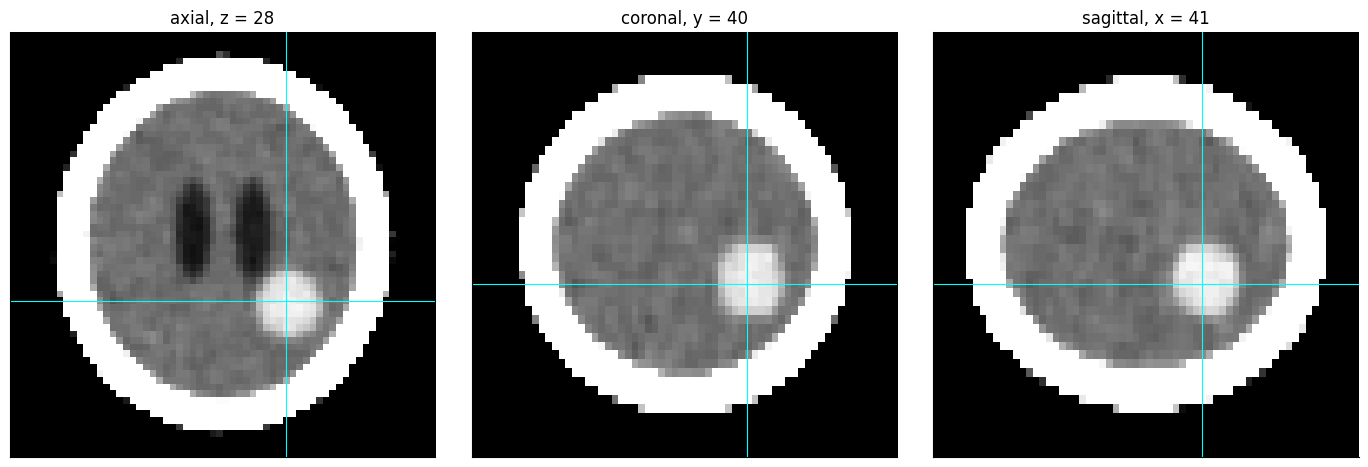

centroid is 2.9 mm from the ground-truth tumour centroid


In [3]:
def window(a, W, L):
    return np.clip((a - (L - W / 2)) / W, 0, 1)

# TODO 1
inside = ndimage.binary_fill_holes(vol > 300) & ~(vol > 300)
inside = ndimage.binary_erosion(inside, iterations=3)
candidates = inside & (vol > 55) & (vol < 90)

# TODO 2
lab, n_comp = ndimage.label(candidates)
sizes = ndimage.sum(np.ones_like(lab), lab, range(1, n_comp + 1))
lesion = lab == (int(np.argmax(sizes)) + 1)
cz, cy, cx = [int(round(v)) for v in ndimage.center_of_mass(lesion)]
print(f"lesion centroid (z, y, x) = ({cz}, {cy}, {cx}), largest component = {int(lesion.sum())} voxels")

# TODO 3
fig, axes = plt.subplots(1, 3, figsize=(14, 4.6))
axes[0].imshow(window(vol[cz, :, :], 80, 40), cmap="gray")
axes[0].axhline(cy, color="cyan", lw=0.8); axes[0].axvline(cx, color="cyan", lw=0.8)
axes[0].set_title(f"axial, z = {cz}")
axes[1].imshow(window(vol[:, cy, :], 80, 40), cmap="gray", aspect=ASPECT)
axes[1].axhline(cz, color="cyan", lw=0.8); axes[1].axvline(cx, color="cyan", lw=0.8)
axes[1].set_title(f"coronal, y = {cy}")
axes[2].imshow(window(vol[:, :, cx], 80, 40), cmap="gray", aspect=ASPECT)
axes[2].axhline(cz, color="cyan", lw=0.8); axes[2].axvline(cy, color="cyan", lw=0.8)
axes[2].set_title(f"sagittal, x = {cx}")
for a in axes: a.set_xticks([]); a.set_yticks([])

plt.tight_layout(); plt.show()

# TODO 4 (evaluation only)
tc = np.array(ndimage.center_of_mass(labels == 5))
dist_mm = float(np.linalg.norm((np.array([cz, cy, cx]) - tc) * np.array(SPACING)))
print(f"centroid is {dist_mm:.1f} mm from the ground-truth tumour centroid")

**Reflection:** Why did you need the erosion step? Explain in terms of the **partial-volume effect** and the
overlapping intensity ranges the lecture lists as a transfer-function challenge (Slide 28).

_Your answer:_

Without erosion, the 55-90 HU test also selects a thin shell just under the skull: voxels straddling the bone-brain boundary mix bright bone with dimmer brain into mid-range values - the partial-volume effect - and bone and brain have overlapping intensity ranges, which the lecture lists as a core transfer-function challenge (Slide 28). That shell is thin but huge in area, so it would swamp the small real lesion when taking the largest component. Eroding the brain mask 3 times peels the shell away so only voxels deep inside the brain remain, where the true lesion is the dominant connected piece.

## Task 3 — Tumour Volume and Its Threshold Sensitivity (Request #3)

**Real-world usage:** Tumour volume drives treatment decisions and response assessment, so its uncertainty must be
reported.

**Why this technique:** An **isosurface/segmentation at threshold c** defines the structure — and *the chosen c
strongly influences the resulting geometry* (Slides 19–20, 31–32).

**TODO:**
1. For c in `[45, 50, 55, 60, 65, 70]`, grow the region `vol > c` from your lesion centre (connected component
   containing `(cz, cy, cx)`).
2. For each c, record the voxel count, the volume in mL (`voxels * VOXEL_MM3 / 1000`), and — evaluation only — the
   Dice overlap with `labels == 5`.
3. Plot volume (mL) vs. threshold, and mark the threshold with the best Dice.
4. Print the range of volumes you would report to the surgeon.

,threshold c (HU),voxels,volume (mL),Dice vs truth
0,45,535,19.3,0.929
1,50,464,16.7,0.994
2,55,431,15.5,0.963
3,60,350,12.6,0.860
4,65,273,9.8,0.741
5,70,170,6.1,0.536


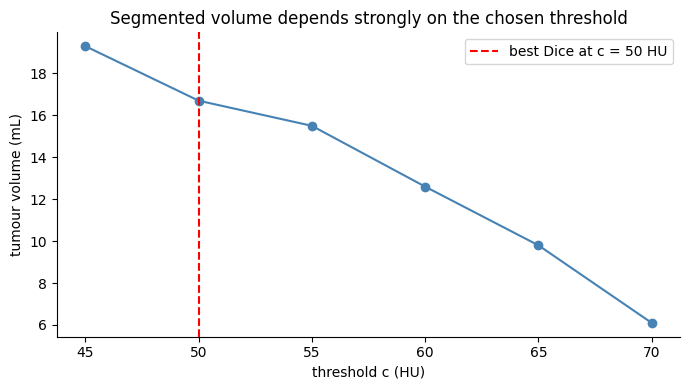

Report to the surgeon: the tumour measures between 6.1 and 19.3 mL depending on the threshold; best-validated estimate 16.7 mL at c = 50 HU.


In [4]:
truth = labels == 5
rows = []
# TODO 1 & 2
for c in [45, 50, 55, 60, 65, 70]:
    mask = vol > c
    labc, nc = ndimage.label(mask)
    idx = labc[cz, cy, cx]
    if idx == 0:                     # centroid voxel dropped below threshold: use largest component
        sizes_c = ndimage.sum(np.ones_like(labc), labc, range(1, nc + 1))
        idx = int(np.argmax(sizes_c)) + 1
    region = labc == idx
    vox = int(region.sum())
    tp = int((region & truth).sum())
    dice = 2 * tp / (vox + int(truth.sum()))
    rows.append({"threshold c (HU)": c, "voxels": vox,
                 "volume (mL)": round(vox * VOXEL_MM3 / 1000, 1),
                 "Dice vs truth": round(dice, 3)})

table = pd.DataFrame(rows)
display(table)

# TODO 3
best = table.loc[table["Dice vs truth"].idxmax(), "threshold c (HU)"]
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(table["threshold c (HU)"], table["volume (mL)"], "-o", color="steelblue")
ax.axvline(best, color="red", ls="--", label=f"best Dice at c = {best} HU")
ax.set_xlabel("threshold c (HU)"); ax.set_ylabel("tumour volume (mL)")
ax.set_title("Segmented volume depends strongly on the chosen threshold")
ax.legend()
plt.tight_layout(); plt.show()

# TODO 4
lo_v, hi_v = table["volume (mL)"].min(), table["volume (mL)"].max()
best_v = table.loc[table["Dice vs truth"].idxmax(), "volume (mL)"]
print(f"Report to the surgeon: the tumour measures between {lo_v:.1f} and {hi_v:.1f} mL depending on the threshold; best-validated estimate {best_v:.1f} mL at c = {best} HU.")

**Reflection:** In real life there is no ground-truth label. How would you choose and justify c for the tumour
board, and how would you *visualize* the uncertainty so the surgeon doesn't treat a single number as exact?

_Your answer:_

With no ground truth I would choose c where the volume curve is least sensitive - the plateau region (here around 45-50 HU, before the curve falls steeply past 55 HU) - and have a radiologist confirm the contour on the MPR. To keep the surgeon from treating one number as exact, I would report the range (about 6-19 mL across plausible thresholds) and show it visually: the volume-vs-threshold curve beside the slices, and the low-c and high-c segmentations overlaid as two contours so the band between them is the visible uncertainty.

## Task 4 — A 3-D Render That Shows the Tumour (Request #4)

**Real-world usage:** Pre-operative 3-D views show a lesion in context with critical structures (here the ventricles).

**Why this technique:** **Direct volume rendering** with a designed **transfer function** — colour to *identify*
materials, opacity to *reveal or suppress* them (Slides 21–27); occlusion is the main enemy (Slide 28).

**TODO:**
1. Render the given `bone_tf` (front view, `axis=1`) — this is the "beautiful skull" the oncologist complained about.
2. Design your own `tumour_tf` with `make_tf([...])` so that: air and soft tissue are fully transparent, bone is
   *almost* transparent (α ≤ 0.01, still gives context), CSF (≈ 5–20 HU) is blue and faint, and the tumour range
   is red. Remember that opacity **accumulates over every sample along a ray**: a thick structure with α ≈ 0.1
   per sample becomes nearly opaque, while a thin one stays faint — use that to your advantage.
3. Render your TF from the front (`axis=1`) **and** from above (`axis=0`), side by side with the bone render.
4. Give the figure a conclusion-style title.

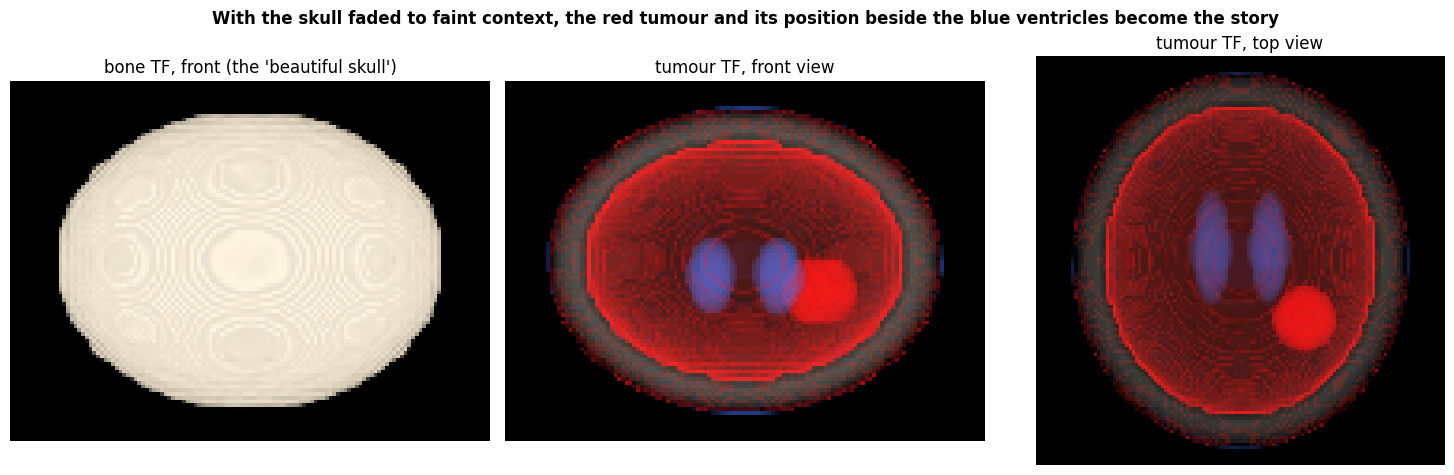

In [5]:
bone_tf = make_tf([(-1000, (0, 0, 0), 0), (200, (0, 0, 0), 0), (400, (1, 0.95, 0.85), 0.3), (1500, (1, 1, 1), 0.6)])

# TODO 2: your transfer function
tumour_tf = make_tf([
    (-1000, (0, 0, 0), 0),
    (0, (0, 0, 0), 0),
    (5, (0.25, 0.45, 1.0), 0.04),     # CSF (ventricles): blue, faint
    (20, (0.25, 0.45, 1.0), 0.04),
    (26, (0, 0, 0), 0),               # between CSF and brain: transparent
    (46, (0, 0, 0), 0),               # brain tissue (~29-45 HU): fully transparent
    (50, (1.0, 0.05, 0.05), 0.12),    # sharp ramp into the tumour band (49-77 HU)
    (90, (1.0, 0.05, 0.05), 0.12),    # red; the tumour is thick, so opacity accumulates along the ray
    (100, (0, 0, 0), 0),
    (400, (1, 0.95, 0.85), 0.006),    # bone: almost transparent, still gives context
    (1500, (1, 1, 1), 0.01),
])

fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))
# TODO 1 & 3: bone render | your TF front view | your TF top view
Cb, Ab = render(vol, bone_tf, axis=1)
Cf, Af = render(vol, tumour_tf, axis=1)
Ct, At = render(vol, tumour_tf, axis=0)
axes[0].imshow(np.clip(Cb, 0, 1)); axes[0].set_title("bone TF, front (the 'beautiful skull')")
axes[1].imshow(np.clip(Cf, 0, 1)); axes[1].set_title("tumour TF, front view")
axes[2].imshow(np.clip(Ct, 0, 1)); axes[2].set_title("tumour TF, top view")
for a in axes: a.axis("off")

# TODO 4: suptitle
fig.suptitle("With the skull faded to faint context, the red tumour and its position beside the blue ventricles become the story",
             fontsize=12, fontweight="bold")
plt.tight_layout(); plt.show()

**Reflection:** Your tumour TF probably also lights up a faint red rim just inside the skull. Which volume-rendering
challenge from Slide 28 causes it? Name one technique from this lecture (hint: Slides 31–32) that would remove it,
and explain why a transfer function alone cannot.

_Your answer:_

The faint red rim is the partial-volume effect again: voxels on the brain-skull border average the two tissues into the tumour's HU band, and a transfer function sees only one voxel's intensity at a time, so it cannot tell a true tumour voxel from a boundary mixture - the overlapping-ranges challenge of Slide 28. A segmentation-first approach (Slides 31-32) - classify voxels using neighbourhood/connected-component information, then render the segmented volume or its isosurface - removes the rim, because classification can use spatial evidence that a per-voxel transfer function never sees.

## Task 5 — The Decision (No Code)

**Reflection (final):** Write a 4–6 sentence note to the tumour board covering the whole notebook. It should:
- State where the lesion is and its volume **as a range** (Task 3), in plain language.
- Recommend which **one** view to open the meeting with (MPR, segmentation overlay, or the 3-D render) and justify
  it with at least one lecture idea (occlusion, slicing exposes internal structure, transfer-function overlap,
  segmentation enables measurement).
- Name one limitation of the 3-D render the board should keep in mind.

_Your final note here:_

The lesion is a compact mass deep in the brain, slightly right of the midline at voxel (z, y, x) = (28, 40, 41) - about 11 cm above the feet-end of the scan and 3 mm off the ground-truth centre. Its volume is 6-19 mL depending on the threshold, with the best-validated estimate about 16.7 mL at c = 50 HU (Dice 0.99), and I would quote that range, not a single number. I recommend opening the meeting with the three-plane MPR: slicing exposes the internal structure with no occlusion, the linked cross-hairs give exact localisation, and it carries no rendering artifacts. The 3-D render is the context shot - it shows the red tumour against the blue ventricles - but the board should remember its faint red rim under the skull is a partial-volume artifact, not extra tumour.